# HydroGuard — Phase 2A: focused EDA and evaluation feasibility

This notebook describes UCI 447 without building prediction features or a model.
Original one-based `cycle_id` and file order are preserved. Targets, the other
condition annotations, stability and all grouping IDs remain **metadata**.
Cycle means, standard deviations and signal distances are **descriptive only**;
no per-cycle feature table, fitted estimator, tuning or final split file is created.

Run from the project root: `uv sync --locked --group eda --python 3.11`, then
`uv run --locked --group eda python scripts/run_eda.py`. In a notebook interface,
select the same uv environment and Run All. Raw data must already be downloaded
with the Phase 1A command. The notebook verifies them and never modifies them.

All numerical findings below come from execution. Measurements are separated from
interpretations and proposed protocols. The whole dataset is explored here, so
none of the candidate validation subsets is an untouched final test set.

In [1]:
%matplotlib inline
import itertools
import platform
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.model_selection import KFold, StratifiedGroupKFold, StratifiedKFold, TimeSeriesSplit

from hydroguard.data import (
    ARCHIVE_SHA256,
    CYCLE_SECONDS,
    EXPECTED_CYCLES,
    PROFILE_COLUMNS,
    SENSOR_RATES,
    TARGET_LABELS,
    audit_dataset,
    consecutive_runs,
    cycle_metadata,
    extraction_inventory,
    load_matrix,
    sha256_file,
    utc_now,
    validate_profile,
    validate_sensor,
    write_json_atomic,
)

ROOT = next(
    path
    for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "pyproject.toml").is_file() and (path / "src/hydroguard/data.py").is_file()
)
RAW = ROOT / "data/raw"
SEED = 2026
COLORS = {0: "#2563a6", 1: "#c87916", 2: "#a83c4b"}
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.18,
        "font.size": 10,
    }
)
pd.set_option("display.max_columns", 24)
pd.set_option("display.max_rows", 80)
runtime = {
    "python": platform.python_version(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "matplotlib": matplotlib.__version__,
    "scikit_learn": sklearn.__version__,
}
display(pd.Series(runtime, name="Executed versions"))

python          3.11.15
numpy             2.4.6
pandas            2.3.3
matplotlib       3.11.2
scikit_learn      1.9.1
Name: Executed versions, dtype: object

## 1. Verified inputs and metadata contract

Use the existing strict loader, validators and read-only audit. No cached CSV is
trusted as an input. Recompute metadata from `profile.txt`, in original row order.
Checksums are derived from the pinned archive through the existing audit. The
Phase 1A report and data exports are not overwritten by this notebook.

In [2]:
manifest_digest_before = sha256_file(RAW / "download.json")
audit, audited_rows = audit_dataset(RAW / "uci447", provenance_path=RAW / "download.json")
assert audit["validation_passed"], audit["errors"]
assert audit["archive_checksum_verified"] and audit["manifest_bound_to_archive"]
raw_hashes_before = {item["file"]: item["sha256"] for item in audit["inventory"]}
profile = validate_profile(load_matrix(RAW / "uci447/profile.txt"))
metadata = pd.DataFrame(cycle_metadata(profile)).set_index("cycle_id", verify_integrity=True)
assert metadata.reset_index().to_dict("records") == audited_rows
assert np.array_equal(metadata.index, np.arange(1, EXPECTED_CYCLES + 1))
assert list(metadata.columns) == list(PROFILE_COLUMNS)
metadata_original = metadata.copy(deep=True)
leakage = metadata["pump_leakage"].to_numpy()
n = len(metadata)
display(
    pd.Series(
        {
            "cycles": n,
            "signals": len(SENSOR_RATES),
            "cycle_seconds_documented": CYCLE_SECONDS,
            "archive_sha256": ARCHIVE_SHA256,
            "complete_duplicate_groups": audit["duplicate_sensor_cycles"]["group_count"],
        }
    )
)
display(metadata.head())

cycles                                                                    2205
signals                                                                     17
cycle_seconds_documented                                                    60
archive_sha256               24128aad2ee45eea7e6b63ebbd9992cdf25d0483a2cebe...
complete_duplicate_groups                                                    0
dtype: object

,cooler_condition_pct,valve_condition_pct,pump_leakage,accumulator_pressure_bar,stability_flag
cycle_id,,,,,
1,3,100,0,130,1
2,3,100,0,130,1
3,3,100,0,130,1
4,3,100,0,130,1
5,3,100,0,130,1


## 2. Target, other condition annotations and stability

Cross-tabulations show both counts and **P(leakage class | condition value)**.
Cramér's V is an unadjusted, descriptive association magnitude from contingency
counts. No significance tests or independent-cycle assumptions are made. Numerical
condition codes are treated as categories here; associations do not establish causes.


cooler_condition_pct: counts, then leakage percentages within each condition


pump_leakage,0,1,2
cooler_condition_pct,,,
3,404,164,164
20,404,164,164
100,413,164,164


pump_leakage,0,1,2
cooler_condition_pct,,,
3,55.19,22.40,22.40
20,55.19,22.40,22.40
100,55.74,22.13,22.13



valve_condition_pct: counts, then leakage percentages within each condition


pump_leakage,0,1,2
valve_condition_pct,,,
73,120,120,120
80,120,120,120
90,120,120,120
100,861,132,132


pump_leakage,0,1,2
valve_condition_pct,,,
73,33.33,33.33,33.33
80,33.33,33.33,33.33
90,33.33,33.33,33.33
100,76.53,11.73,11.73


... (4 outputs left out)

pump_leakage,0,1,2
stability_flag,,,
0,489,480,480
1,732,12,12


pump_leakage,0,1,2
stability_flag,,,
0,33.75,33.13,33.13
1,96.83,1.59,1.59


,label,cycles,share_pct
0,no leakage,1221,55.37
1,weak leakage,492,22.31
2,severe leakage,492,22.31


,cramers_v_descriptive
condition,
cooler_condition_pct,0.0037
valve_condition_pct,0.3072
accumulator_pressure_bar,0.1919
stability_flag,0.6023


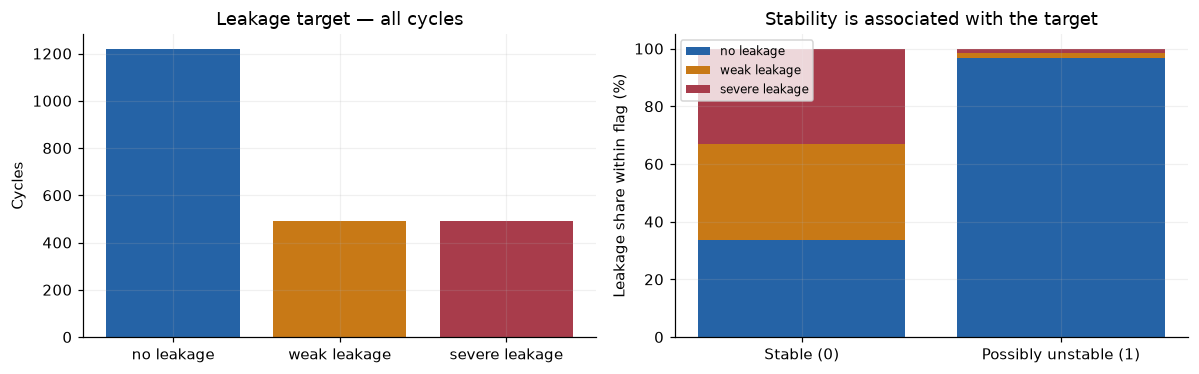

In [3]:
target_counts = metadata["pump_leakage"].value_counts().sort_index()
target_table = pd.DataFrame(
    {
        "label": pd.Series(TARGET_LABELS),
        "cycles": target_counts,
        "share_pct": 100 * target_counts / n,
    }
)
condition_tables = {}
association_rows = []
for column in (
    "cooler_condition_pct",
    "valve_condition_pct",
    "accumulator_pressure_bar",
    "stability_flag",
):
    table = pd.crosstab(metadata[column], metadata["pump_leakage"]).reindex(
        columns=[0, 1, 2], fill_value=0
    )
    conditional = 100 * table.div(table.sum(axis=1), axis=0)
    expected = np.outer(table.sum(axis=1), table.sum(axis=0)) / n
    chi2 = float(np.sum((table.to_numpy() - expected) ** 2 / expected))
    cramer_v = np.sqrt(chi2 / (n * min(table.shape[0] - 1, table.shape[1] - 1)))
    association_rows.append({"condition": column, "cramers_v_descriptive": cramer_v})
    condition_tables[column] = table
    print(f"\n{column}: counts, then leakage percentages within each condition")
    display(table, conditional.round(2))
association = pd.DataFrame(association_rows).set_index("condition")
display(target_table.round(2), association.round(4))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].bar(
    [TARGET_LABELS[v] for v in target_counts.index],
    target_counts,
    color=[COLORS[v] for v in target_counts.index],
)
axes[0].set(ylabel="Cycles", title="Leakage target — all cycles")
stability_table = condition_tables["stability_flag"]
bottom = np.zeros(len(stability_table))
for value in [0, 1, 2]:
    heights = 100 * stability_table[value] / stability_table.sum(axis=1)
    axes[1].bar(
        ["Stable (0)", "Possibly unstable (1)"],
        heights,
        bottom=bottom,
        color=COLORS[value],
        label=TARGET_LABELS[value],
    )
    bottom += heights.to_numpy()
axes[1].set(ylabel="Leakage share within flag (%)", title="Stability is associated with the target")
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

## 3. Original cycle order, configurations and observed blocks

An **observed block** is a maximal run of identical first four profile columns.
A **full condition configuration** is that four-column tuple, including leakage,
even when it returns in nonconsecutive blocks. A **nuisance configuration** is
`(cooler, valve, accumulator)` and excludes leakage and stability. These are three
different metadata definitions, not verified session or experiment IDs.

full_configurations                        144
nuisance_configurations                     48
observed_blocks                            194
full_configurations_in_multiple_blocks      36
nuisance_groups_with_all_classes            48
same_target_adjacent_pairs                2168
adjacent_pairs                            2204
dtype: int64

,value,start_cycle_id,end_cycle_id,cycles
0,3,1,732,732
1,20,733,1464,732
2,100,1465,2205,741


cycles  \
cooler_condition_pct valve_condition_pct pump_leakage accumulator_pressure_bar           
20                   100                 0            90                           221   
100                  100                 0            90                           230   
3                    100                 0            130                          221   
                                                      115                           21   
100                  100                 0            100                           21   
                                                      130                           21   
20                   100                 0            100                           21   
                                                      130                           21   
3                    100                 0            100                           21   
                                                      90                            21   
100                  100                 0            115                           21   
20                   100                 0            115                           21   

                                                                                observed_blocks  \
cooler_condition_pct valve_condition_pct pump_leakage accumulator_pressure_bar                    
20                   100                 0            90                                      4   
100                  100                 0            90                                      4   
3                    100                 0            130                                     3   
                                                      115                                     3   
100                  100                 0            100                                     3   
                                                      130                                     3   
20                   100                 0            100                                     3   
                                                      130                                     3   
3                    100                 0            100                                     3   
                                                      90                                      3   
100                  100                 0            115                                     3   
20                   100                 0            115                                     3   

                                                                                first_cycle_id  \
cooler_condition_pct valve_condition_pct pump_leakage accumulator_pressure_bar                   
20                   100                 0            90                                   733   
100                  100                 0            90                                  1465   
3                    100                 0            130                                    1   
                                                      115                                  334   
100                  100                 0            100                                 1931   
                                                      130                                 1665   
20                   100                 0            100                                 1199   
                                                      130                                  933   
3                    100                 0            100                                  467   
                                                      90                                   600   
100                  100                 0            115                                 1798   
20                   100                 0            115                                 1066   

                                                           

col_0,0,1,2
min,10.0,10.0,10.0
median,10.0,10.0,10.0
max,230.0,11.0,11.0


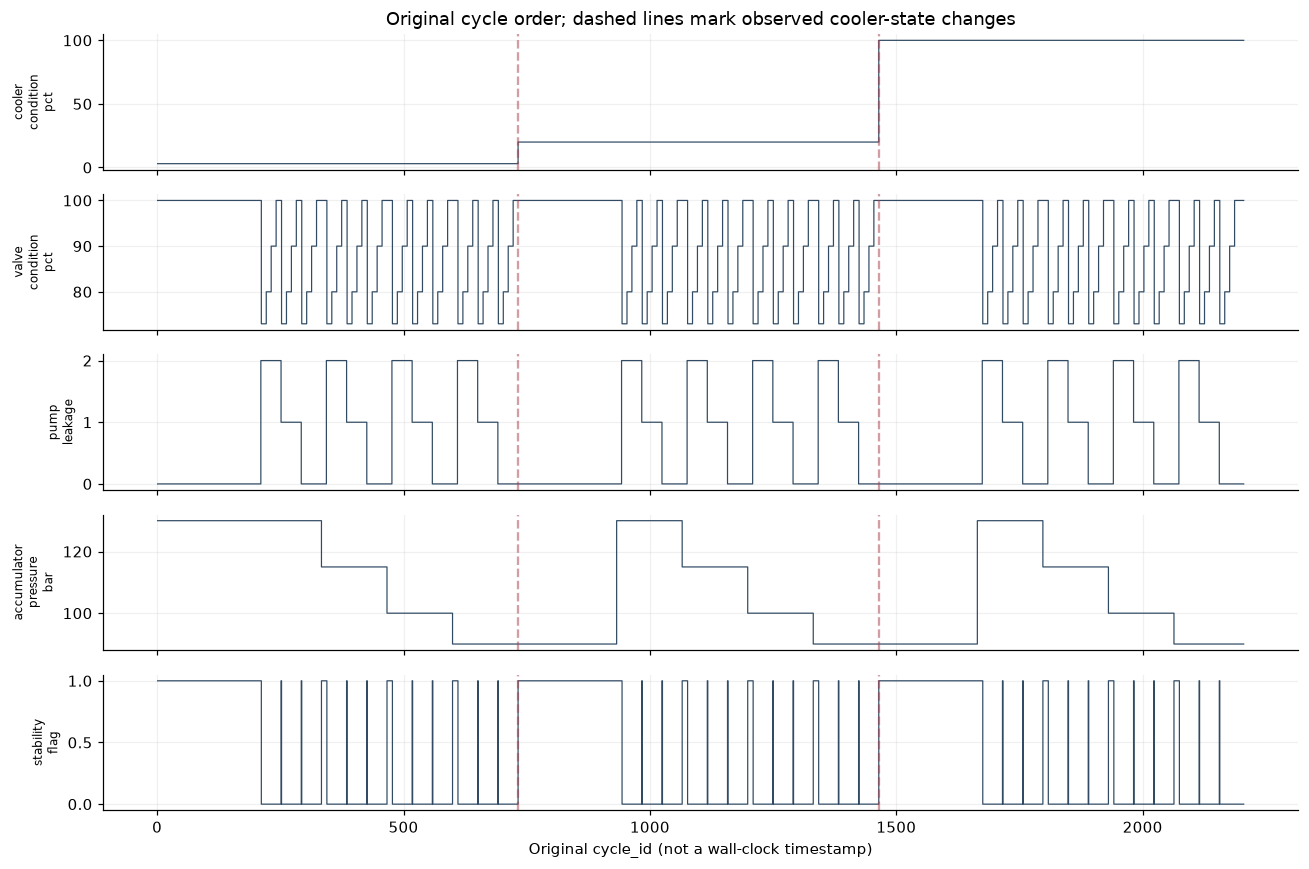

In [4]:
full_columns = list(PROFILE_COLUMNS[:4])
nuisance_columns = ["cooler_condition_pct", "valve_condition_pct", "accumulator_pressure_bar"]
full_index = pd.MultiIndex.from_frame(metadata[full_columns])
nuisance_index = pd.MultiIndex.from_frame(metadata[nuisance_columns])
full_ids, _ = pd.factorize(full_index, sort=True)
nuisance_ids, _ = pd.factorize(nuisance_index, sort=True)
block_ids = np.cumsum(np.r_[True, full_ids[1:] != full_ids[:-1]])
block_rows = pd.DataFrame(
    {"full_id": full_ids, "nuisance_id": nuisance_ids, "block_id": block_ids}, index=metadata.index
)
configuration_summary = metadata.groupby(full_columns, sort=True).size().rename("cycles").to_frame()
configuration_summary["observed_blocks"] = [
    len(np.unique(block_ids[full_ids == group])) for group in range(len(configuration_summary))
]
configuration_summary["first_cycle_id"] = [
    int(np.flatnonzero(full_ids == g)[0] + 1) for g in range(len(configuration_summary))
]
configuration_summary["last_cycle_id"] = [
    int(np.flatnonzero(full_ids == g)[-1] + 1) for g in range(len(configuration_summary))
]
nuisance_support = pd.crosstab(nuisance_ids, leakage).reindex(columns=[0, 1, 2], fill_value=0)
cooler_runs = pd.DataFrame(consecutive_runs(metadata["cooler_condition_pct"].to_numpy()))
ordering_summary = {
    "full_configurations": len(np.unique(full_ids)),
    "nuisance_configurations": len(np.unique(nuisance_ids)),
    "observed_blocks": len(np.unique(block_ids)),
    "full_configurations_in_multiple_blocks": int(
        (configuration_summary.observed_blocks > 1).sum()
    ),
    "nuisance_groups_with_all_classes": int((nuisance_support > 0).all(axis=1).sum()),
    "same_target_adjacent_pairs": int(np.sum(leakage[1:] == leakage[:-1])),
    "adjacent_pairs": n - 1,
}
display(pd.Series(ordering_summary), cooler_runs)
display(configuration_summary.sort_values("observed_blocks", ascending=False).head(12))
display(nuisance_support.agg(["min", "median", "max"]))
fig, axes = plt.subplots(5, 1, figsize=(12, 8), sharex=True)
for ax, column in zip(axes, PROFILE_COLUMNS, strict=True):
    ax.step(metadata.index, metadata[column], where="mid", color="#314b64", linewidth=0.8)
    ax.set_ylabel(column.replace("_", "\n"), fontsize=8)
    for end in cooler_runs.end_cycle_id.iloc[:-1]:
        ax.axvline(end + 0.5, color="#a83c4b", alpha=0.5, linestyle="--")
axes[0].set_title("Original cycle order; dashed lines mark observed cooler-state changes")
axes[-1].set_xlabel("Original cycle_id (not a wall-clock timestamp)")
fig.tight_layout()
plt.show()

## 4. Representative sensors and descriptive changes

The displayed sensors are chosen in advance to span pressure (PS1), motor power
(EPS1), two volume flows (FS1/FS2), temperature (TS1) and vibration (VS1), not by
predictive performance. All 17 sensors are loaded and validated one at a time.
Cycle means/standard deviations stay in memory for description and are never
exported as prediction features.

For raw waveform examples, take the lexicographically first nuisance configuration
with stable cycles in all three target classes, then the middle source-order cycle
within each class. This matching reduces three annotated component differences;
it does not remove temporal/thermal or unmeasured confounding and is not a random
sample of the population.

For similarity, compare per-sensor waveform RMSE divided by the sensor's global
sample standard deviation, then the root mean square of those normalized distances
over all 17 sensors (equal sensor weight). Global scales are descriptive only,
never a fitted feature transformer. Zero variance would be reported as an error.

In [5]:
stable_support = pd.crosstab(nuisance_ids[profile[:, 4] == 0], leakage[profile[:, 4] == 0]).reindex(
    columns=[0, 1, 2], fill_value=0
)
matched_group = int(stable_support.index[(stable_support > 0).all(axis=1)][0])
example_positions = [
    np.flatnonzero((nuisance_ids == matched_group) & (leakage == label) & (profile[:, 4] == 0))
    for label in [0, 1, 2]
]
example_positions = [positions[len(positions) // 2] for positions in example_positions]
examples = metadata.iloc[example_positions].copy()
display(examples)

rng = np.random.default_rng(SEED)
adjacent_pairs = np.column_stack((np.arange(n - 1), np.arange(1, n)))
random_pairs_set = set()
while len(random_pairs_set) < n - 1:
    left, right = sorted(rng.integers(0, n, size=2).tolist())
    if right - left > 1:
        random_pairs_set.add((left, right))
random_pairs = np.array(sorted(random_pairs_set))
same_configuration_pool = []
for group in np.unique(full_ids):
    positions = np.flatnonzero(full_ids == group)
    same_configuration_pool.extend(
        (a, b) for a, b in itertools.combinations(positions, 2) if b - a > 1
    )
same_configuration_pool = np.array(same_configuration_pool)
selected_pairs = rng.choice(len(same_configuration_pool), size=n - 1, replace=False)
pair_sets = {
    "adjacent": adjacent_pairs,
    "random_nonadjacent": random_pairs,
    "same_full_configuration_nonadjacent": same_configuration_pool[selected_pairs],
}
assert all(len(pairs) == n - 1 for pairs in pair_sets.values())
assert np.all(
    full_ids[pair_sets["same_full_configuration_nonadjacent"][:, 0]]
    == full_ids[pair_sets["same_full_configuration_nonadjacent"][:, 1]]
)


def normalized_pair_distances(matrix, pairs, scale):
    values = np.empty(len(pairs))
    for start in range(0, len(pairs), 128):
        batch = pairs[start : start + 128]
        differences = matrix[batch[:, 0]] - matrix[batch[:, 1]]
        values[start : start + len(batch)] = np.sqrt(np.mean(differences**2, axis=1)) / scale
    return values


representatives = ["PS1", "EPS1", "FS1", "FS2", "TS1", "VS1"]
units = {"PS1": "bar", "EPS1": "W", "FS1": "l/min", "FS2": "l/min", "TS1": "°C", "VS1": "mm/s"}
descriptive = {}
waveform_examples = {}
sensor_rows = []
distances = {name: {} for name in pair_sets}
for sensor in SENSOR_RATES:
    matrix = load_matrix(RAW / "uci447" / f"{sensor}.txt")
    validate_sensor(matrix, sensor)
    scale = float(matrix.std())
    assert scale > 0, f"Constant sensor: {sensor}"
    means = matrix.mean(axis=1)
    descriptive[sensor] = pd.DataFrame(
        {"mean": means, "std": matrix.std(axis=1)}, index=metadata.index
    )
    sensor_rows.append(
        {
            "sensor": sensor,
            "global_sample_std": scale,
            "cycle_mean_min": float(means.min()),
            "cycle_mean_max": float(means.max()),
            "mean_lag1_correlation": float(np.corrcoef(means[:-1], means[1:])[0, 1]),
        }
    )
    for name, pairs in pair_sets.items():
        distances[name][sensor] = normalized_pair_distances(matrix, pairs, scale)
    if sensor in representatives:
        waveform_examples[sensor] = matrix[example_positions].copy()
    del matrix
sensor_description = pd.DataFrame(sensor_rows).set_index("sensor")
display(sensor_description.round(4))

,cooler_condition_pct,valve_condition_pct,pump_leakage,accumulator_pressure_bar,stability_flag
cycle_id,,,,,
698,3,73,0,90,0
657,3,73,1,90,0
616,3,73,2,90,0


,global_sample_std,cycle_mean_min,cycle_mean_max,mean_lag1_correlation
sensor,,,,
PS1,16.1333,155.3915,180.9227,0.7159
PS2,48.1032,104.4063,131.5891,0.7199
PS3,0.9347,0.8403,2.0234,0.8930
PS4,4.2976,0.0000,10.2071,0.9938
PS5,0.5766,8.3658,9.9785,0.9999
PS6,0.5499,8.3215,9.8566,0.9999
EPS1,218.2222,2361.7473,2740.6410,0.7889
FS1,3.2138,2.0186,6.7227,0.8104
FS2,0.4495,8.8575,10.4031,0.9999


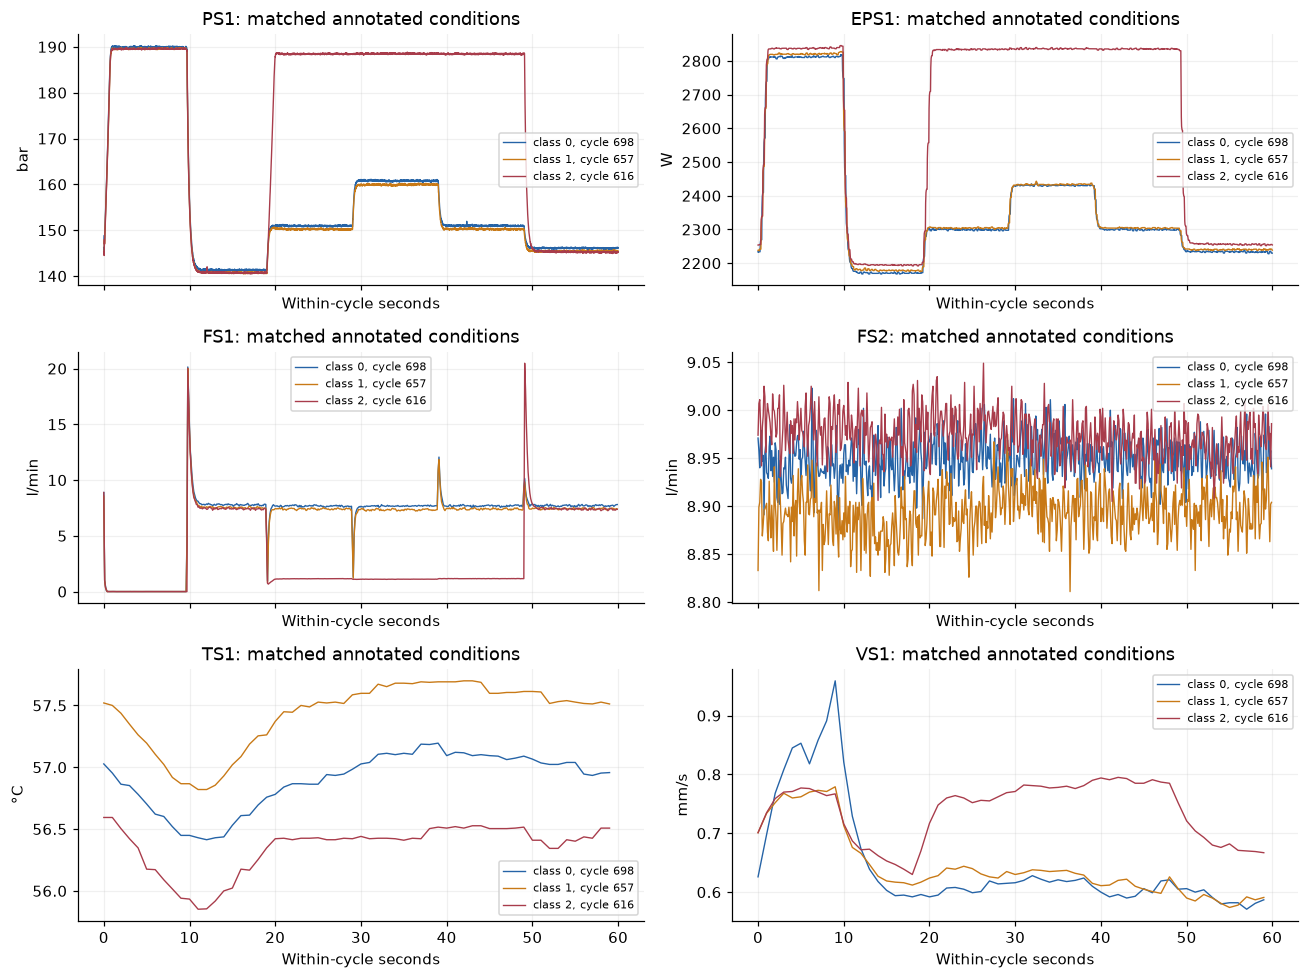

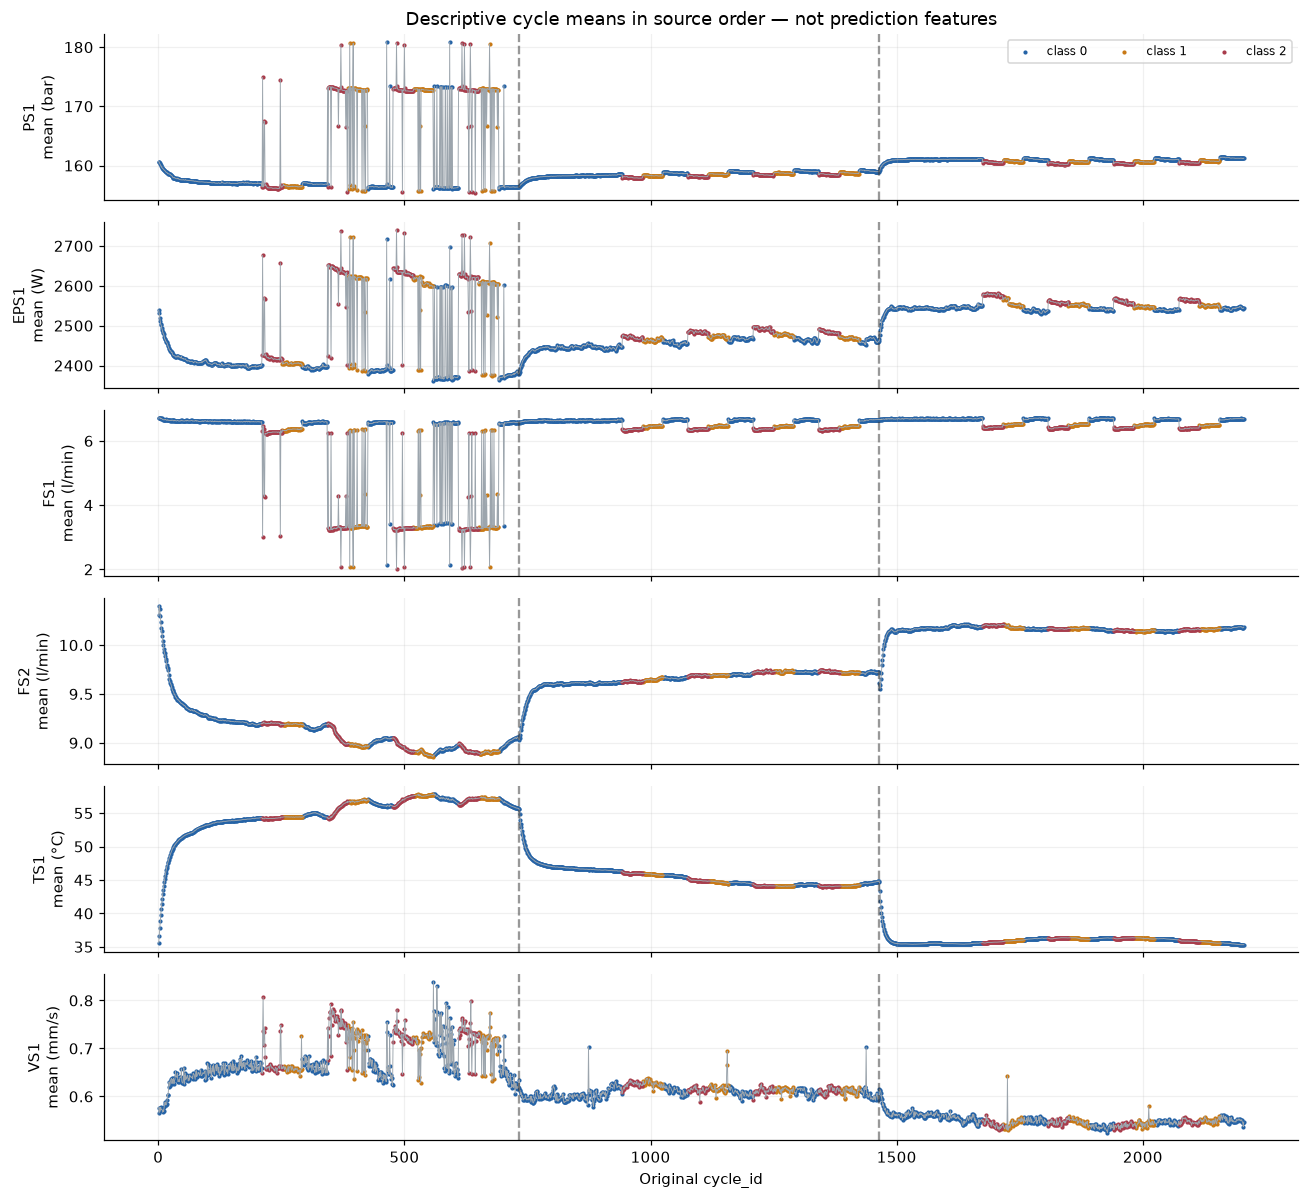

,sensor,cooler_pct,cycle_mean_median,cycle_mean_q25,cycle_mean_q75
0,PS1,3,157.0863,156.4311,172.7229
1,PS1,20,158.4537,158.2536,158.7689
2,PS1,100,160.9231,160.5899,161.0376
3,EPS1,3,2407.9366,2395.5151,2607.6362
4,EPS1,20,2465.4933,2448.5827,2474.1769
5,EPS1,100,2546.5453,2541.8808,2553.7403
6,FS1,3,6.5416,3.3275,6.5996
7,FS1,20,6.6248,6.4227,6.6439
8,FS1,100,6.6671,6.4732,6.6922
9,FS2,3,9.0609,8.9554,9.2042


In [6]:
fig, axes = plt.subplots(3, 2, figsize=(12, 9), sharex=True)
for ax, sensor in zip(axes.flat, representatives, strict=True):
    times = np.arange(waveform_examples[sensor].shape[1]) / SENSOR_RATES[sensor]
    for index, label in enumerate([0, 1, 2]):
        ax.plot(
            times,
            waveform_examples[sensor][index],
            color=COLORS[label],
            linewidth=0.9,
            label=f"class {label}, cycle {example_positions[index] + 1}",
        )
    ax.set(
        title=f"{sensor}: matched annotated conditions",
        ylabel=units[sensor],
        xlabel="Within-cycle seconds",
    )
    ax.legend(fontsize=7)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(6, 1, figsize=(12, 11), sharex=True)
for ax, sensor in zip(axes, representatives, strict=True):
    values = descriptive[sensor]["mean"]
    ax.plot(metadata.index, values, color="#9ca5ad", linewidth=0.6)
    for label in [0, 1, 2]:
        ax.scatter(
            metadata.index[leakage == label],
            values[leakage == label],
            s=3,
            color=COLORS[label],
            label=f"class {label}",
            rasterized=True,
        )
    for end in cooler_runs.end_cycle_id.iloc[:-1]:
        ax.axvline(end + 0.5, color="#333333", linestyle="--", alpha=0.5)
    ax.set_ylabel(f"{sensor}\nmean ({units[sensor]})")
axes[0].set_title("Descriptive cycle means in source order — not prediction features")
axes[0].legend(ncol=3, fontsize=8)
axes[-1].set_xlabel("Original cycle_id")
fig.tight_layout()
plt.show()

regime_rows = []
for sensor in representatives:
    for cooler, rows in metadata.groupby("cooler_condition_pct", sort=True):
        values = descriptive[sensor].loc[rows.index, "mean"]
        regime_rows.append(
            {
                "sensor": sensor,
                "cooler_pct": int(cooler),
                "cycle_mean_median": float(values.median()),
                "cycle_mean_q25": float(values.quantile(0.25)),
                "cycle_mean_q75": float(values.quantile(0.75)),
            }
        )
regime_summary = pd.DataFrame(regime_rows)
display(regime_summary.round(4))

## 5. Neighbor similarity, repetition and what cannot be inferred

Compare adjacent pairs with a fixed random nonadjacent sample and a sample of
nonadjacent pairs sharing the **entire four-component configuration**, including
target. Pair sampling does not use sensor values. The matched comparator controls
only the recorded conditions; its lag distribution differs from adjacent pairs.
Pairs overlap and are dependent: the quantiles below are descriptive, not confidence
intervals. Similarity is not exact duplication and cannot establish independence.

,pairs,median_distance,q25_distance,q75_distance,median_cycle_lag
pair_set,,,,,
adjacent,2204,0.06816,0.05761,0.10391,1.0
random_nonadjacent,2204,1.03980,0.48495,1.30888,638.5
same_full_configuration_nonadjacent,2204,0.14898,0.08787,0.31526,72.0
adjacent_same_full_configuration,2011,0.06589,0.05690,0.09184,1.0
adjacent_configuration_change,193,0.14290,0.10649,0.20627,1.0


,adjacent,random_nonadjacent,same_full_configuration_nonadjacent
PS1,0.00933,0.16683,0.01720
PS2,0.00637,0.14793,0.00842
PS3,0.11137,0.51123,0.12329
PS4,0.00000,0.13406,0.00000
PS5,0.05497,1.13517,0.07810
PS6,0.05821,1.13691,0.08031
EPS1,0.02079,0.39103,0.04697
FS1,0.05006,0.28946,0.06727
FS2,0.04430,1.07504,0.08899
TS1,0.00576,1.11756,0.06094


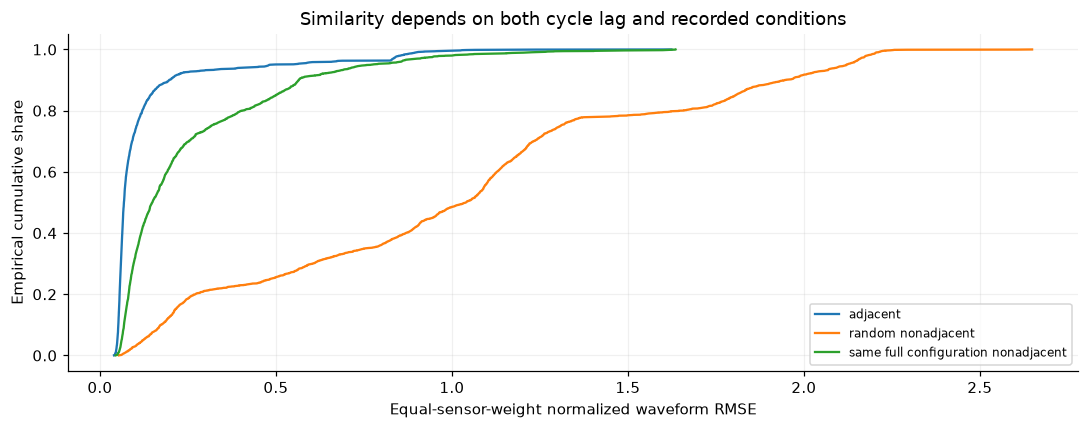

In [7]:
aggregate_distance = {
    name: np.sqrt(np.mean(np.column_stack(list(sensor_values.values())) ** 2, axis=1))
    for name, sensor_values in distances.items()
}
similarity_rows = []
for name, values in aggregate_distance.items():
    pairs = pair_sets[name]
    similarity_rows.append(
        {
            "pair_set": name,
            "pairs": len(values),
            "median_distance": float(np.median(values)),
            "q25_distance": float(np.quantile(values, 0.25)),
            "q75_distance": float(np.quantile(values, 0.75)),
            "median_cycle_lag": float(np.median(pairs[:, 1] - pairs[:, 0])),
        }
    )
same_adjacent = full_ids[:-1] == full_ids[1:]
for name, mask in [
    ("adjacent_same_full_configuration", same_adjacent),
    ("adjacent_configuration_change", ~same_adjacent),
]:
    values = aggregate_distance["adjacent"][mask]
    similarity_rows.append(
        {
            "pair_set": name,
            "pairs": len(values),
            "median_distance": float(np.median(values)),
            "q25_distance": float(np.quantile(values, 0.25)),
            "q75_distance": float(np.quantile(values, 0.75)),
            "median_cycle_lag": 1.0,
        }
    )
similarity = pd.DataFrame(similarity_rows).set_index("pair_set")
per_sensor_similarity = pd.DataFrame(
    {
        name: {sensor: float(np.median(values)) for sensor, values in by_sensor.items()}
        for name, by_sensor in distances.items()
    }
)
display(similarity.round(5), per_sensor_similarity.round(5))
fig, ax = plt.subplots(figsize=(10, 4))
for name, values in aggregate_distance.items():
    sorted_values = np.sort(values)
    ax.plot(
        sorted_values, np.arange(1, len(values) + 1) / len(values), label=name.replace("_", " ")
    )
ax.set(
    xlabel="Equal-sensor-weight normalized waveform RMSE",
    ylabel="Empirical cumulative share",
    title="Similarity depends on both cycle lag and recorded conditions",
)
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

## 6. Evaluation feasibility — temporary indices only

No estimator is fitted. Candidate train/validation indices exist only in memory;
only aggregate diagnostics are written. The all-zero placeholder required by the
splitter API is not a feature matrix. The metadata frame is never reordered.

Compare random stratification, contiguous blocked folds, forward-only folds,
grouping by observed blocks, grouping by full condition configurations and grouping
by target-free nuisance configurations. Also inspect leave-one-cooler-state-out
as a severe domain-shift diagnostic. Nuisance groups pool all repetitions of the
same `(cooler, valve, accumulator)` combination across targets and original cycles.

For blocked/nuisance folds, remove training candidates within 5, 20 or 60 cycle
positions of any validation cycle. These are **sensitivity probes**, not established
decorrelation times. Counts omitted by gaps do not mean deletion from the dataset.

In [8]:
def nearest_position_distance(rows, reference):
    if len(reference) == 0:
        return np.full(len(rows), np.inf)
    reference = np.sort(reference)
    positions = np.searchsorted(reference, rows)
    left = reference[np.maximum(positions - 1, 0)]
    right = reference[np.minimum(positions, len(reference) - 1)]
    return np.minimum(np.abs(rows - left), np.abs(rows - right))


def purge_near_validation(train, validation, gap):
    return train[nearest_position_distance(train, validation) > gap]


assert np.array_equal(
    purge_near_validation(np.array([0, 1, 2, 6, 7, 8]), np.array([3, 4, 5]), 2), [0, 8]
)
assert np.array_equal(nearest_position_distance(np.array([0, 5, 9]), np.array([2, 7])), [2, 2, 2])
placeholder = np.zeros((n, 1))
random_folds = list(
    StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(placeholder, leakage)
)
blocked_folds = list(KFold(n_splits=5, shuffle=False).split(placeholder))
nuisance_folds = list(
    StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED).split(
        placeholder, leakage, nuisance_ids
    )
)
candidate_schemes = {"random_stratified_5fold": random_folds}
for gap in [0, 5, 20, 60]:
    candidate_schemes[f"blocked_gap{gap}"] = [
        (purge_near_validation(train, validation, gap), validation)
        for train, validation in blocked_folds
    ]
    candidate_schemes[f"nuisance_group_gap{gap}"] = [
        (purge_near_validation(train, validation, gap), validation)
        for train, validation in nuisance_folds
    ]
for name, groups in [("observed_block_group", block_ids), ("full_configuration_group", full_ids)]:
    candidate_schemes[name] = list(
        StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED).split(
            placeholder, leakage, groups
        )
    )
candidate_schemes["forward_only_gap20"] = list(
    TimeSeriesSplit(n_splits=5, gap=20).split(placeholder)
)
candidate_schemes["leave_cooler_state_out"] = [
    (np.flatnonzero(profile[:, 0] != state), np.flatnonzero(profile[:, 0] == state))
    for state in sorted(metadata.cooler_condition_pct.unique())
]


def split_diagnostics(name, fold, train, validation):
    assert not np.intersect1d(train, validation).size
    assert np.all(np.diff(train) > 0) and np.all(np.diff(validation) > 0)
    closest = nearest_position_distance(validation, train)
    row = {
        "scheme": name,
        "fold": fold,
        "train_cycles": len(train),
        "validation_cycles": len(validation),
        "unused_cycles": n - len(train) - len(validation),
        "train_before_validation_only": bool(len(train) and train.max() < validation.min()),
        "min_cycle_distance": int(closest.min()) if np.isfinite(closest.min()) else None,
        "validation_with_train_neighbor_pct": float(100 * np.mean(closest == 1)),
    }
    for label in [0, 1, 2]:
        row[f"train_class_{label}"] = int(np.sum(leakage[train] == label))
        row[f"validation_class_{label}"] = int(np.sum(leakage[validation] == label))
        row[f"train_unstable_class_{label}"] = int(
            np.sum((leakage[train] == label) & (profile[train, 4] == 1))
        )
        row[f"validation_unstable_class_{label}"] = int(
            np.sum((leakage[validation] == label) & (profile[validation, 4] == 1))
        )
    for key, groups in [
        ("nuisance", nuisance_ids),
        ("full_configuration", full_ids),
        ("block", block_ids),
    ]:
        row[f"shared_{key}_groups"] = len(np.intersect1d(groups[train], groups[validation]))
        row[f"validation_seen_{key}_pct"] = float(
            100 * np.mean(np.isin(groups[validation], groups[train]))
        )
    for column in nuisance_columns:
        values = metadata[column].to_numpy()
        row[f"unseen_{column}_levels"] = len(set(values[validation]) - set(values[train]))
    membership = np.zeros(n, dtype=np.int8)
    membership[train], membership[validation] = 1, 2
    row["cross_partition_adjacent_pairs"] = int(
        np.sum(
            ((membership[:-1] == 1) & (membership[1:] == 2))
            | ((membership[:-1] == 2) & (membership[1:] == 1))
        )
    )
    return row


fold_diagnostics = pd.DataFrame(
    [
        split_diagnostics(name, fold, train, validation)
        for name, folds in candidate_schemes.items()
        for fold, (train, validation) in enumerate(folds, start=1)
    ]
)
for name, folds in candidate_schemes.items():
    if name != "forward_only_gap20":
        assert np.array_equal(
            np.sort(np.concatenate([validation for _, validation in folds])), np.arange(n)
        )
    for train, validation in folds:
        if name.startswith("nuisance_group"):
            assert not np.intersect1d(nuisance_ids[train], nuisance_ids[validation]).size
        if name == "forward_only_gap20":
            assert train.max() < validation.min()
        if name.endswith("gap20"):
            assert nearest_position_distance(train, validation).min() > 20

summary_rows = []
for name, rows in fold_diagnostics.groupby("scheme", sort=False):
    summary_rows.append(
        {
            "scheme": name,
            "folds": len(rows),
            "train_min": int(rows.train_cycles.min()),
            "train_max": int(rows.train_cycles.max()),
            "validation_min": int(rows.validation_cycles.min()),
            "validation_max": int(rows.validation_cycles.max()),
            "min_train_class_count": int(
                rows[[f"train_class_{i}" for i in [0, 1, 2]]].to_numpy().min()
            ),
            "min_validation_class_count": int(
                rows[[f"validation_class_{i}" for i in [0, 1, 2]]].to_numpy().min()
            ),
            "max_shared_nuisance_groups": int(rows.shared_nuisance_groups.max()),
            "max_shared_full_configs": int(rows.shared_full_configuration_groups.max()),
            "max_shared_blocks": int(rows.shared_block_groups.max()),
            "max_unseen_condition_levels": int(
                rows[[f"unseen_{column}_levels" for column in nuisance_columns]].to_numpy().max()
            ),
            "min_train_unstable_class_1": int(rows.train_unstable_class_1.min()),
            "min_train_unstable_class_2": int(rows.train_unstable_class_2.min()),
            "neighbor_exposure_pct_mean": float(rows.validation_with_train_neighbor_pct.mean()),
            "min_cycle_distance": int(rows.min_cycle_distance.min()),
            "min_validation_unstable_class_1": int(rows.validation_unstable_class_1.min()),
            "min_validation_unstable_class_2": int(rows.validation_unstable_class_2.min()),
        }
    )
feasibility_summary = pd.DataFrame(summary_rows).set_index("scheme")
display(feasibility_summary.round(2))
for scheme in [
    "random_stratified_5fold",
    "blocked_gap20",
    "nuisance_group_gap20",
    "forward_only_gap20",
    "leave_cooler_state_out",
]:
    print(f"\n{scheme}: class support and configuration overlap")
    display(
        fold_diagnostics.loc[
            fold_diagnostics.scheme == scheme,
            [
                "fold",
                "train_cycles",
                "validation_cycles",
                "train_class_0",
                "train_class_1",
                "train_class_2",
                "validation_class_0",
                "validation_class_1",
                "validation_class_2",
                "shared_nuisance_groups",
                "shared_full_configuration_groups",
                "validation_with_train_neighbor_pct",
            ],
        ]
    )

,folds,train_min,train_max,validation_min,validation_max,min_train_class_count,min_validation_class_count,max_shared_nuisance_groups,max_shared_full_configs,max_shared_blocks,max_unseen_condition_levels,min_train_unstable_class_1,min_train_unstable_class_2,neighbor_exposure_pct_mean,min_cycle_distance,min_validation_unstable_class_1,min_validation_unstable_class_2
scheme,,,,,,,,,,,,,,,,,
random_stratified_5fold,5,1764,1764,441,441,393,98,48,133,145,0,7,9,95.24,1,0,2
blocked_gap0,5,1764,1764,441,441,369,82,7,5,2,0,9,9,0.36,1,2,2
nuisance_group_gap0,5,1679,1866,339,526,389,92,0,0,0,0,9,9,13.06,1,2,2
blocked_gap5,5,1754,1759,441,441,369,82,6,4,2,0,9,9,0.00,6,2,2
nuisance_group_gap5,5,1394,1626,339,526,289,92,0,0,0,0,6,6,0.00,6,2,2
blocked_gap20,5,1724,1744,441,441,357,82,5,4,1,0,9,8,0.00,21,2,2
nuisance_group_gap20,5,774,1328,339,526,118,92,0,0,0,0,3,4,0.00,21,2,2
blocked_gap60,5,1644,1704,441,441,328,82,5,3,1,0,8,8,0.00,61,2,2
nuisance_group_gap60,5,510,1088,339,526,42,92,0,0,0,1,2,1,0.00,61,2,2



random_stratified_5fold: class support and configuration overlap


,fold,train_cycles,validation_cycles,train_class_0,train_class_1,train_class_2,validation_class_0,validation_class_1,validation_class_2,shared_nuisance_groups,shared_full_configuration_groups,validation_with_train_neighbor_pct
0,1,1764,441,976,394,394,245,98,98,48,132,95.011338
1,2,1764,441,977,394,393,244,98,99,48,133,94.784580
2,3,1764,441,977,394,393,244,98,99,48,131,95.691610
3,4,1764,441,977,393,394,244,99,98,48,130,94.784580
4,5,1764,441,977,393,394,244,99,98,48,129,95.918367



blocked_gap20: class support and configuration overlap


,fold,train_cycles,validation_cycles,train_class_0,train_class_1,train_class_2,validation_class_0,validation_class_1,validation_class_2,shared_nuisance_groups,shared_full_configuration_groups,validation_with_train_neighbor_pct
25,1,1744,441,924,410,410,277,82,82,1,1,0.0
26,2,1724,441,908,406,410,277,82,82,4,2,0.0
27,3,1724,441,988,369,367,195,123,123,1,1,0.0
28,4,1724,441,904,410,410,277,82,82,5,4,0.0
29,5,1744,441,1018,357,369,195,123,123,5,2,0.0



nuisance_group_gap20: class support and configuration overlap


,fold,train_cycles,validation_cycles,train_class_0,train_class_1,train_class_2,validation_class_0,validation_class_1,validation_class_2,shared_nuisance_groups,shared_full_configuration_groups,validation_with_train_neighbor_pct
30,1,824,526,577,123,124,322,102,102,0,0,0.0
31,2,1328,339,846,246,236,133,103,103,0,0,0.0
32,3,774,496,533,123,118,312,92,92,0,0,0.0
33,4,1094,339,775,164,155,133,103,103,0,0,0.0
34,5,1131,505,649,246,236,321,92,92,0,0,0.0



forward_only_gap20: class support and configuration overlap


,fold,train_cycles,validation_cycles,train_class_0,train_class_1,train_class_2,validation_class_0,validation_class_1,validation_class_2,shared_nuisance_groups,shared_full_configuration_groups,validation_with_train_neighbor_pct
55,1,350,367,261,41,48,148,123,96,2,2,0.0
56,2,717,367,389,164,164,256,41,70,0,0,0.0
57,3,1084,367,665,205,214,150,123,94,3,3,0.0
58,4,1451,367,795,328,328,254,41,72,0,0,0.0
59,5,1818,367,1069,369,380,152,123,92,3,3,0.0



leave_cooler_state_out: class support and configuration overlap


,fold,train_cycles,validation_cycles,train_class_0,train_class_1,train_class_2,validation_class_0,validation_class_1,validation_class_2,shared_nuisance_groups,shared_full_configuration_groups,validation_with_train_neighbor_pct
60,1,1473,732,817,328,328,404,164,164,0,0,0.136612
61,2,1473,732,817,328,328,404,164,164,0,0,0.273224
62,3,1464,741,808,328,328,413,164,164,0,0,0.134953


## 7. Interpretation and proposal boundary

- **Measured:** contingency tables, ordered signal changes, exact duplicate audit,
  waveform distance distributions and candidate fold support/overlap diagnostics.
- **Interpretation:** adjacent similarity, condition persistence and repeated
  configurations make cycle-level random validation vulnerable to optimistic
  interpolation estimates. They do not quantify model leakage or error without
  a later model, and group separation does not establish independent experiments.
- **Proposal:** favor target-free nuisance-configuration grouping for an in-rig
  unseen-condition-combination estimand, subject to class support after temporal
  gap sensitivity checks. Supplement with forward blocked validation for ordered
  transfer; keep random stratification as an interpolation diagnostic. Final
  protocol, gap and estimand require review, not automatic acceptance.
- Keep all stability flags. Future scores must report class counts and stability
  strata; unstable weak/severe leakage have very small support. No model choice,
  fitted preprocessing, predictions or tuning is performed in this notebook.

Read `docs/eda-findings.md` for executed observations and `docs/validation-plan.md`
for the proposed protocol and unresolved decisions. Method references:
[cross-validation guide](https://scikit-learn.org/stable/modules/cross_validation.html),
[StratifiedGroupKFold](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedGroupKFold.html),
[TimeSeriesSplit](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.TimeSeriesSplit.html).

In [9]:
assert metadata.equals(metadata_original), "Metadata order or values changed"
assert extraction_inventory(RAW / "uci447") == raw_hashes_before, "Raw files changed"
assert sha256_file(RAW / "uci447.zip") == ARCHIVE_SHA256
assert sha256_file(RAW / "download.json") == manifest_digest_before
assert n == EXPECTED_CYCLES
summary = {
    "generated_at_utc": utc_now(),
    "phase": "2A descriptive EDA and split feasibility only",
    "runtime": runtime,
    "seed": SEED,
    "archive_sha256": ARCHIVE_SHA256,
    "raw_files_unchanged": True,
    "metadata_order_unchanged": True,
    "target_counts": {str(k): int(v) for k, v in target_counts.items()},
    "association": association.reset_index().to_dict("records"),
    "matched_examples": examples.reset_index().to_dict("records"),
    "cooler_runs": cooler_runs.to_dict("records"),
    "ordering": ordering_summary,
    "nuisance_support": nuisance_support.reset_index().to_dict("records"),
    "sensor_description": sensor_description.reset_index().to_dict("records"),
    "cooler_regime_descriptive_summary": regime_summary.to_dict("records"),
    "similarity": similarity.reset_index().to_dict("records"),
    "per_sensor_similarity": per_sensor_similarity.reset_index()
    .rename(columns={"index": "sensor"})
    .to_dict("records"),
    "feasibility_summary": feasibility_summary.reset_index().to_dict("records"),
    "fold_diagnostics": fold_diagnostics.to_dict("records"),
    "no_models_or_feature_pipeline": True,
    "no_final_split_files": True,
}
# Aggregate descriptive results only: no sensor feature rows or fold membership lists.
summary_path = ROOT / "data/processed/eda-summary.json"
write_json_atomic(summary_path, summary)
print(f"PASS: read-only EDA completed for {n} cycles; metadata and raw checksums unchanged")
print(f"Aggregate descriptive evidence (Git-ignored): {summary_path.relative_to(ROOT)}")

PASS: read-only EDA completed for 2205 cycles; metadata and raw checksums unchanged
Aggregate descriptive evidence (Git-ignored): data\processed\eda-summary.json
